#### importing packages and getting data ready

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

import matplotlib.pyplot as plt
plt.style.use("Solarize_Light2")


In [2]:
data_clean = "goodreads_onestar_clean.csv"   # cleaned data, one-star reviews only
TEXT_COL = "review_text"   # name of the column with the review text
MIN_WORDS = 10             # skip reviews shorter than this many words
SEED = 42 # random seed for reproducibility

HIDE = ["alice", "wonderland", "carroll", "silverstein", "peter"] # common titles and authors to hide

In [3]:
one_star = pd.read_csv(data_clean) # turning into a DataFrame
one_star = one_star.dropna(subset=[TEXT_COL]) # dropping reviews with no text
one_star = one_star[one_star[TEXT_COL].str.split().str.len() >= MIN_WORDS] # splitting review text into list of words, counting them, and keeping only reviews with at least MIN_WORDS words

print(f"1-star reviews: {len(one_star)}") # printing the number of 1-star reviews after filtering

1-star reviews: 8801


# Pre-Analysis Code: Hand Labeling Method

## Flagging reviews about "appropriateness"

In [46]:
def compare_groups(texts_a, texts_b):  # scoring words and phrases that are distinctive to one group vs another
    texts_a = list(texts_a) # a positive score = more typical of group A, negative score = more typical of group B
    texts_b = list(texts_b)

    counter = CountVectorizer( # using CountVectorizer to count words and phrases in the two groups
        ngram_range=(1, 2), # defining upper and lower limit of words to be extracted
        min_df=15,    # words/phrases must appear in 15+ reviews
        token_pattern=r"(?u)\b\w[\w']*\b",   # keeps negations and other words with apostrophes like "don't" 
    )
    counts = counter.fit_transform(texts_a + texts_b) # makes table of counts of each word/phrase in each review
        
    a_review_number = len(texts_a) # how many reviews in group A and group B
    b_review_number = len(texts_b)
    count_a = np.asarray(counts[:a_review_number].sum(axis=0)).ravel() # selects group A reviews, sums the counts of each term across all reviews, and flattens into list of numbers
    count_b = np.asarray(counts[a_review_number:].sum(axis=0)).ravel() # selects group B reviews, sums the counts of each term across all reviews, and flattens into list of numbers

    baseline = count_a + count_b # how many times each term appears in all reviews (group A + group B)
    baseline_total = baseline.sum() # sums across all terms to get the total number of term appearances in all reviews

    odds_a = np.log((count_a + baseline) / (count_a.sum() + baseline_total - count_a - baseline)) # computes the log-odds of each term appearing in group A vs group B, with a baseline to avoid division by zero
    odds_b = np.log((count_b + baseline) / (count_b.sum() + baseline_total - count_b - baseline))
    difference = odds_a - odds_b

    # Turn the difference into a score that accounts for how much data there is
    uncertainty = np.sqrt(1 / (count_a + baseline) + 1 / (count_b + baseline)) # this calculates uncertainty for each term based on its counts in both groups and the baseline 
    score = difference / uncertainty # dividing to get a z-score-like measure

    results = pd.DataFrame({ # putting everything into a DataFrame 
        "term": counter.get_feature_names_out(),
        "score": score,
        "count_A": count_a,
        "count_B": count_b,
    })

        
    for name in HIDE: # hiding common titles and authors from the results
        results = results[~results["term"].str.contains(r"\b" + name + r"\b")]

    return results.sort_values("score", ascending=False).reset_index(drop=True) # sorting the results by score in descending order and resetting the index


In [47]:
# catching reviews containing inappropriate, not appropriate, unsuitable, or offensive, and their variants
TRIGGER_PATTERN = (   # deciding which reviews count as complaints about inappropriateness, using regex to match various phrases
    r"(?:age[- ])?inappropriate\w*" # use of the word "inappropriate" or "age-inappropriate"
    r"|\b(?:not|isn't|wasn't|aren't|weren't)\s+(?:\w+\s+){0,2}(?:age[- ])?appropriate" # negating words followed by "age appropriate" or "appropriate"
    r"|unsuitable|not suitable|offensive|offend|vulgar|crude|perverse|immoral|sinful"  # other words/phrases that indicate inappropriateness
    r"|too (?:scary|violent|graphic|dark|mature|disturbing|sexual|adult|intense|creepy)"
    r"|too (?:old|young|mature|advanced) for"
    r"|not (?:for|meant for|intended for) (?:\w+ ){0,2}(?:kids|children|young)"
    r"|not (?:very )?(?:child|kid|family)[- ]friendly"
)
WINDOW = 10   # how many words on each side of trigger_pattern to look at

In [48]:
has_trigger = one_star[TEXT_COL].str.contains(TRIGGER_PATTERN, case=False, regex=True) # checking which reviews contain the trigger pattern, ignoring case and using regex
matched = one_star[has_trigger]
others = one_star[~has_trigger]
print(f"{len(matched):,} of {len(one_star):,} 1-star reviews contain an " # printing the number and percentage of 1-star reviews that contain an inappropriateness complaint
      f"inappropriateness complaint ({len(matched) / len(one_star):.1%})")

257 of 8,801 1-star reviews contain an inappropriateness complaint (2.9%)


In [49]:
def snippet(text, width=12):
    m = re.search(TRIGGER_PATTERN, text, flags=re.I) # finding the first occurrence of the trigger pattern in the text
    before = " ".join(text[:m.start()].split()[-width:]) # taking the words before the trigger pattern, splitting them into a list, and keeping only the last 12 words
    after = " ".join(text[m.end():].split()[:width]) # taking the words after the trigger pattern, splitting them into a list, and keeping only the first 12 words
    return f"{before} [[{m.group(0)}]] {after}" # returning a string that includes the words before and after the trigger pattern


matched = matched.copy()
matched["snippet"] = matched[TEXT_COL].apply(snippet) # running the function snippet on each review in the matched DataFrame and creating a new column called "snippet" that contains the result

pd.set_option("display.max_colwidth", None) # letting the entire snippet show up in the output, instead of being truncated
print("\n25 random examples (read these first):")
print(matched[["book_id", "snippet"]].sample(min(25, len(matched)), # printing 25 random examples of the matched reviews, showing the book_id and the snippet, and using a random seed for reproducibility
                                             random_state=SEED).to_string())


25 random examples (read these first):
       book_id                                                                                                                                                                     snippet
6403   6054449         cute couple". Not only does the dismissal of true literary art somewhat [[offend]] me, but the description is grossly inaccurate. My three main thoughts throughout
7205  22033266                         up. For instance, she spends a chapter on the doctrine of the [[sinful]] nature of humankind--that people are born with selfish desires and want to
3603     19302          confine itself to morality tales, but this book crosses the line into [[immoral]] ity-without-consequences tales and there is nothing positive to be found within.
873      30118                  children will never hear this trash again. I can't get over how [[not for children]] these poems are and they're very obviously not meant to adults. YUCK.
105     237564           

In [50]:
distinct = compare_groups(matched[TEXT_COL], others[TEXT_COL]) # running the compare_groups function on the matched and others DataFrames to get the most distinctive words in the matched reviews
distinct = distinct[~distinct["term"].str.contains("appropriat|suitab|offen")] # removing the trigger words from the results, so that the most distinctive words are not just the trigger words themselves
distinct.to_csv("words_inappropriate_vs_other_1star.csv", index=False)
print("\nMost distinctive words in reviews that call something inappropriate:")
print(distinct.head(40).round(2).to_string())


Most distinctive words in reviews that call something inappropriate:
             term  score  count_A  count_B
6         old for   4.03       18        5
7         too old   3.32       18       15
8            rose   3.26       23       30
10          lowry   2.96       19       25
11            god   2.89       55      213
12           dark   2.79       45      159
13      political   2.78       18       26
14             oz   2.75       25       54
15  www goodreads   2.71       15       18
16  goodreads com   2.66       15       19
17       the dark   2.43       21       49
18      https www   2.37       14       22
19         people   2.36      145     1135
20         my kid   2.35       17       34
21          bible   2.27       23       66
22      christian   2.21       25       80
23        appeals   2.15       10       13
24       children   2.15      182     1627
25          of oz   2.10       14       29
26          https   2.07       14       30
27          susan   2.05   

#### CSV file containing random sample of 200 reviews about "appropriateness" with column to add HAND LABELS

In [51]:
# taking a random sample of 200 reviews that contain inappropriateness complaints
to_code = matched[["book_id", TEXT_COL, "snippet"]].sample(
    min(200, len(matched)), random_state=SEED)
to_code["reason"] = ""
to_code.to_csv("inappropriate_to_code.csv", index=False) # saving reviews to a CSV file for hand labeling
print("\nSaved inappropriate_to_code.csv with", len(to_code), "reviews to label")


Saved inappropriate_to_code.csv with 200 reviews to label


In [52]:
inappropriate_to_code = pd.read_csv("inappropriate_to_code.csv") # reading the hand-labeled CSV file back into a DataFrame

## Looking at NOT-flagged reviews (reviews not about "appropriateness")

In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

print("\nWords most typical of the NOT-flagged reviews:")
print(distinct.sort_values("score").head(40).round(2).to_string(index=False)) # printing the 40 words with the lowest score, which are the most typical of the NOT-flagged reviews



Words most typical of the NOT-flagged reviews:
             term  score  count_A  count_B
                i  -1.67     1172    22292
           boring  -1.16       19      758
               it  -0.99      796    14444
          strange  -0.98        1      221
         couldn't  -0.94       15      555
           a half  -0.93        3      260
            story  -0.92      174     3580
       half stars  -0.92        2      228
             half  -0.91       11      453
             nice  -0.90        8      378
          one and  -0.85        6      309
              put  -0.84       10      401
        it wasn't  -0.84        1      170
           i read  -0.81       25      710
     the pictures  -0.81        3      217
        the first  -0.81       28      768
      interesting  -0.80       16      517
            nancy  -0.80        0      126
           i love  -0.79        5      261
    illustrations  -0.77       40      990
           always  -0.77       15      480
      

In [54]:
print("\n15 random NOT-flagged reviews (first 300 characters):")
for text in others[TEXT_COL].sample(15, random_state=SEED): # a loop taking a random sample of 15 NOT-flagged reviews
    print("-", text[:300].replace("\n", " "), "\n")


15 random NOT-flagged reviews (first 300 characters):
- Might have given this a 2, as it's slight but might appeal to older kids. But the last page foldout means this book's shelf life will be shortened, which makes my investment of library money in it even more depressing. 

- Did not like this; the cute illustrations had sooo much going on that the point of the story was lost. Took me a few pages to even figure it out/find the object as it was so not direct. For the target age group I feel like this would be just a HUGE miss unless you want to find another nose/face/tail 

- This is the worst kind of "literature" to expose your children to. It's filled with stereotypes and fake accents. It's sad that Judy Schachner doesn't know any better. 

- Would have been good except it glorified Zen and a Zen master. That is something that doesn't need to be mentioned in a young kids book. 

- Not really feeling this one. At all. Sometimes I think that in between Yolen getting a really good sto

### Topic Model of NOT-flagged reviews

In [55]:
NUMBER_OF_TOPICS = 8
tfidf = TfidfVectorizer(stop_words="english", min_df=10, max_df=0.5) # using TF-IDF to assign weights to words in the reviews
X = tfidf.fit_transform(others[TEXT_COL]) # transforming the NOT-flagged reviews into a matrix
nmf = NMF(n_components=NUMBER_OF_TOPICS, random_state=SEED, init="nndsvda", max_iter=400) # using NMF to find topics in the NOT-flagged reviews, with 8 topics, a random seed for reproducibility, and a maximum of 400 iterations
doc_topics = nmf.fit_transform(X) # transforming the matrix of NOT-flagged reviews into a matrix of topic weights for each review
terms = tfidf.get_feature_names_out() # getting the feature names (words) from the TF-IDF vectorizer

others = others.copy()
others["topic"] = doc_topics.argmax(axis=1) # assigning each review to the topic with the highest weight
for i, weights in enumerate(nmf.components_): # a loop that goes through each topic and prints the top 10 words for that topic, along with the number of reviews assigned to that topic
    top_words = [terms[j] for j in weights.argsort()[::-1][:10]]
    n_reviews = (others["topic"] == i).sum()
    print(f"\nTopic {i} ({n_reviews:,} reviews): {', '.join(top_words)}")


Topic 0 (2,481 reviews): children, books, little, good, way, child, time, series, love, reading

Topic 1 (643 reviews): didn, care, finish, enjoy, like, wasn, characters, work, make, appeal

Topic 2 (1,073 reviews): read, books, ve, hated, school, reading, grade, remember, time, worst

Topic 3 (1,175 reviews): story, illustrations, text, cute, nice, pictures, words, good, liked, stars

Topic 4 (957 reviews): just, couldn, finish, maybe, bad, wasn, funny, really, sorry, weird

Topic 5 (434 reviews): boring, finish, plot, thought, long, ugh, finished, good, reading, really

Topic 6 (859 reviews): don, know, kids, think, understand, kid, want, maybe, remember, classic

Topic 7 (922 reviews): like, really, did, felt, wanted, thought, feel, people, didnt, say


# Hand Label Analysis

In [14]:
from sklearn.preprocessing import MultiLabelBinarizer

df = pd.read_csv("inappropriate_reviews_labels.csv") # reading in the hand-labeled reviews from the CSV file
df["labels"] = df["labels"].fillna("").str.split(";").apply(   # splitting the labels column into a list of labels for each review, including labels separated by semicolons, and filling in any missing values with an empty string
    lambda xs: [x.strip() for x in xs if x.strip()] # removing any stray spaces and empty strings from the list of labels
)
mlb = MultiLabelBinarizer()   
y = pd.DataFrame(mlb.fit_transform(df["labels"]), columns=mlb.classes_, index=df.index) # transforming the list of labels into a binary matrix of 0s and 1s, where each column corresponds to a label and each row corresponds to a review
df = df.join(y) # adding the label matrix to the original DataFrame, so that each review has a column for each label indicating whether it was flagged for that label or not

In [15]:
df["labels"] = df["labels"].apply(lambda xs: ["ableism" if x == "abelism" else x for x in xs]) # fixing typo in the labels column

In [16]:
df["labels"] = df["labels"].apply(lambda xs: ["age-appropriateness" if x == "age" else x for x in xs]) # changing "age" to "age-appropriateness" for a clearer label in the labels column

In [17]:
# filtering the dataframe to only include reviews that have been flagged as inappropriate, and selecting the relevant columns for further analysis
df_inappropriate =df[df["is_inappropriate_complaint"] == "yes"][["review_id", "book_id", "review_text", "labels", "notes"]] 



In [18]:
df_inappropriate_llm = df_inappropriate[["review_id", "book_id", "review_text", "labels","notes"]].copy()
df_inappropriate_llm["llm_labels"] = None
df_inappropriate_llm["llm_reasoning"] = None

In [ ]:
df_inappropriate_llm.to_csv("inappropriate_reviews_llm_labels.csv", index=False)


In [20]:
df_inappropriate.drop(df_inappropriate.index[0:3], inplace=True) # filtering out the first three rows which appear to be copy-pasted reviews

/var/folders/4h/xc8h1h651vj9bkgkh5c8471r0000gn/T/ipykernel_91441/3373744388.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_inappropriate.drop(df_inappropriate.index[0:3], inplace=True) # filtering out the first three rows which appear to be copy-pasted reviews


In [21]:
len(df_inappropriate) # total number of reviews that have been flagged as inappropriate

163

In [44]:
df_inappropriate.head(1)

,review_id,book_id,review_text,labels,notes,has_age
4,8271a9e037ebe67dab6376fe498dbcf9,3350841,"Earlier in our studies of church history, we read the wonderful work of Simonetta Carr in the Christian Biographies for Young Readers Series. It has ruined us. \n In this book specifically (we, unfortunately, own several from the series) there is a horrible theological error that undermines the gospel and Christian living: \n ""So William said [to Hindu's who wanted them to sacrifice to their god, kali], ""I serve a God who lives and loves all life. My God forgives, and He expects no living sacrifice."" \n WHAT?!?! Ms. Meloche and the editors should read Romans 12:1-2 or Hebrews Chapter 10, not to mention the entire Old Testament. \n This series is awful. Listed on CBD for ages 5-10, and on Amazon as 4 and up, this designation is completely off, even arbitrary. I would recommend these books, maybe, for preschool. For some reason, they decided to use rhyming verse, a literary style that greatly appeals to the preschool set. But in that format, the serious topics of missions, paganism, and the confrontation between light and darkness are addressed. \n This is everything I hate about cheery ""christian"" literature. A sing-song, happy-happy-clap-clap approach to the very real war of the ages is infuriatingly inappropriate in preparing our children to stand for the LORD. If this kind of God will never let anything uncomfortable happen to you sweet child theology is what you are looking for, Meloche's work will suit you fine. But if you are looking to raise up godly children who are equipped to know, love and serve the amazing, awesome, Creative God, do yourself a favor: Don't buy any books in this series. \n Excellent alternatives, which I have reviewed on Goodreads are: \n Christian Biographies for Young Readers (Series), Simonetta Carr \n https://www.goodreads.com/series/8395... \n Trial & Tribulation (A single book overview of Church History), Hannula \n https://www.goodreads.com/review/show... \n History Lives Series by Brandon & Mindy Withrow \n https://www.goodreads.com/review/show...","[religion, age-appropriateness]",copy,True


In [45]:
# counting how many reviews have been flagged for each label, by exploding the list of labels into separate rows and counting how many times each label occurs
df_inappropriate["labels"].explode().value_counts() 

labels
age-appropriateness    114
scary/dark              39
bad-influence           31
racism                  25
crude-language          23
illustrations           18
violence                15
religion                10
drugs/alcohol           10
sexism                  10
body-shaming             4
abuse                    4
ableism                  4
classism                 4
preachy                  3
non-factual              2
witchcraft               2
sexuality                1
Name: count, dtype: int64

In [23]:
# reviews explicitly flagged for age-appropriateness versus not flagged for age-appropriateness
exploded = df_inappropriate["labels"].explode()
age_ids = exploded[exploded == "age-appropriateness"].index.unique()

df_inappropriate = df_inappropriate.copy()
df_inappropriate["has_age"] = df_inappropriate.index.isin(age_ids)

df_age_only = df_inappropriate[df_inappropriate["has_age"]]
df_not_age = df_inappropriate[~df_inappropriate["has_age"]]

print(df_inappropriate["has_age"].value_counts())

pct_of_age = round(df_inappropriate["has_age"].sum() / len(df_inappropriate) * 100, 1) # calculating the percentage of reviews that have been flagged for age-appropriateness

num_age = df_inappropriate["has_age"].sum()
num_total = len(df_inappropriate)
print(f"{num_age} of {num_total} reviews ({num_age / num_total * 100:.1f}%) are labeled age-appropriateness")

has_age
True     114
False     49
Name: count, dtype: int64
114 of 163 reviews (69.9%) are labeled age-appropriateness


In [24]:
import matplotlib.pyplot as plt

In [25]:
df_inappropriate[df_inappropriate["labels"] == "age-appropriateness"].head(1) # filtering the dataframe to only include reviews that have been flagged for age-appropriateness, and selecting the relevant columns for further analysis

,review_id,book_id,review_text,labels,notes,has_age


In [26]:
counts = df_inappropriate["labels"].explode().value_counts().head(10)
pct_of_reviews = (counts / len(df_inappropriate) * 100).round(1) # calculating the percentage of reviews that have been flagged for each label
print(pct_of_reviews)

labels
age-appropriateness    69.9
scary/dark             23.9
bad-influence          19.0
racism                 15.3
crude-language         14.1
illustrations          11.0
violence                9.2
religion                6.1
drugs/alcohol           6.1
sexism                  6.1
Name: count, dtype: float64


In [27]:
# looking at the number of reviews for every label and the percentage of those reviews that have also been flagged as age-appropriateness, to see which labels are most often associated with age-appropriateness

label_column = df_inappropriate[["labels"]].copy() # copy of dataframe with only the labels column. double-brackets are used to keep it as a dataframe instead of a series, so that we can use the explode method on it
label_column["has_age"] = label_column["labels"].apply(lambda xs: "age-appropriateness" in xs) # checking if the list of labels for each review contains "age-appropriateness" and creating a new column called "has_age" that contains a boolean value indicating whether or not the review has been flagged as age-appropriateness
label_column = label_column.explode("labels").dropna(subset=["labels"]) # turning the list of labels for each review into separate rows, so that each row corresponds to a single label for a single review, and dropping any rows with missing values in the labels column
label_column = label_column[label_column["labels"] != "age-appropriateness"] # filtering out the age-appropriateness label from the dataframe, so that we can see how many reviews have been flagged for other labels in addition to age-appropriateness

result = (label_column.groupby("labels")["has_age"] # grouping the dataframe by label and counting how many reviews have been flagged as age-appropriateness for each label, and how many reviews have been flagged for each label in total
             .agg(n_reviews="size", also_age_appropriate="sum"))

result["pct"] = (result["also_age_appropriate"] / result["n_reviews"] * 100).round(1) # calculating the percentage of reviews that have been flagged as age-appropriateness for each label
result = result.sort_values("pct", ascending=False) # sorting results by descending percentage of reviews
print(result)

                n_reviews  also_age_appropriate    pct
labels                                                
bad-influence          31                    31  100.0
body-shaming            4                     4  100.0
drugs/alcohol          10                    10  100.0
sexuality               1                     1  100.0
crude-language         23                    20   87.0
violence               15                    13   86.7
illustrations          18                    13   72.2
sexism                 10                     7   70.0
preachy                 3                     2   66.7
scary/dark             39                    23   59.0
non-factual             2                     1   50.0
witchcraft              2                     1   50.0
religion               10                     5   50.0
abuse                   4                     2   50.0
classism                4                     1   25.0
ableism                 4                     1   25.0
racism    

The following labels had 100% of their reviews also labeled with "age-appropriateness": 
"bad-influence", "body-shaming", "drugs/alcohol", "sexuality"

In [28]:
# filtering the dataframe to only include reviews that have been flagged as age-appropriateness, and creating a copy of the filtered dataframe to avoid modifying the original dataframe
df_age = df_inappropriate[df_inappropriate["labels"].apply(lambda xs: "age-appropriateness" in xs)].copy() 

n = len(df_age)
n # total number of reviews that have been flagged as age-appropriateness

114

In [56]:
df_age.head(1)

,review_id,book_id,review_text,labels,notes,has_age
4,8271a9e037ebe67dab6376fe498dbcf9,3350841,"Earlier in our studies of church history, we read the wonderful work of Simonetta Carr in the Christian Biographies for Young Readers Series. It has ruined us. \n In this book specifically (we, unfortunately, own several from the series) there is a horrible theological error that undermines the gospel and Christian living: \n ""So William said [to Hindu's who wanted them to sacrifice to their god, kali], ""I serve a God who lives and loves all life. My God forgives, and He expects no living sacrifice."" \n WHAT?!?! Ms. Meloche and the editors should read Romans 12:1-2 or Hebrews Chapter 10, not to mention the entire Old Testament. \n This series is awful. Listed on CBD for ages 5-10, and on Amazon as 4 and up, this designation is completely off, even arbitrary. I would recommend these books, maybe, for preschool. For some reason, they decided to use rhyming verse, a literary style that greatly appeals to the preschool set. But in that format, the serious topics of missions, paganism, and the confrontation between light and darkness are addressed. \n This is everything I hate about cheery ""christian"" literature. A sing-song, happy-happy-clap-clap approach to the very real war of the ages is infuriatingly inappropriate in preparing our children to stand for the LORD. If this kind of God will never let anything uncomfortable happen to you sweet child theology is what you are looking for, Meloche's work will suit you fine. But if you are looking to raise up godly children who are equipped to know, love and serve the amazing, awesome, Creative God, do yourself a favor: Don't buy any books in this series. \n Excellent alternatives, which I have reviewed on Goodreads are: \n Christian Biographies for Young Readers (Series), Simonetta Carr \n https://www.goodreads.com/series/8395... \n Trial & Tribulation (A single book overview of Church History), Hannula \n https://www.goodreads.com/review/show... \n History Lives Series by Brandon & Mindy Withrow \n https://www.goodreads.com/review/show...","[religion, age-appropriateness]",copy,True


In [30]:
others = (df_age["labels"].explode() # counting how many reviews have been flagged for each label
          .loc[lambda s: s != "age-appropriateness"] # filtering out the "age-appropriateness" label from the counts, so that we can see how many reviews have been flagged for other labels in addition to age-appropriateness
          .value_counts())
print(others)

labels
bad-influence     31
scary/dark        23
crude-language    20
illustrations     13
violence          13
drugs/alcohol     10
sexism             7
religion           5
racism             5
body-shaming       4
abuse              2
preachy            2
non-factual        1
sexuality          1
witchcraft         1
ableism            1
classism           1
Name: count, dtype: int64


In [31]:
pct_others_and_age = (others / n * 100).round(1) # calculating the percentage of age-appropriateness labeled reviews that have been flagged with another label
print(pct_others_and_age)

labels
bad-influence     27.2
scary/dark        20.2
crude-language    17.5
illustrations     11.4
violence          11.4
drugs/alcohol      8.8
sexism             6.1
religion           4.4
racism             4.4
body-shaming       3.5
abuse              1.8
preachy            1.8
non-factual        0.9
sexuality          0.9
witchcraft         0.9
ableism            0.9
classism           0.9
Name: count, dtype: float64


# Visualizations

### Visualizing top ten themes for reviews marked as inappropriate complaint. 

#### Themes shown as a percentage of total reviews. Because some reviews may be flagged with multiple labels, the percentage totals don't equal 100.

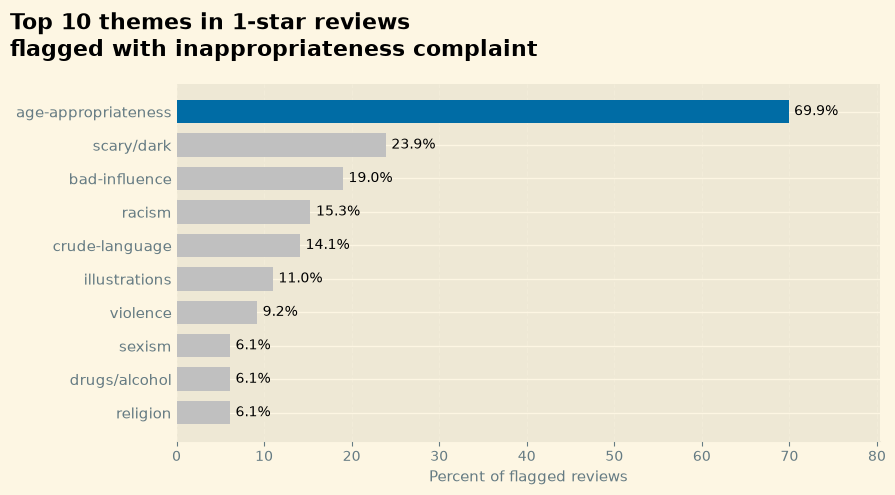

In [32]:

data = pct_of_reviews.sort_values() # sorting values from smallest to largest

colors = ["#006CA5" if name == "age-appropriateness" else "#C0C0C0" for name in data.index] # coloring in largest bar

fig, ax = plt.subplots(figsize=(9, 5)) # sizing the figure
bars = ax.barh(data.index, data.values, color=colors, height=0.7) # creating horizontal bars for each theme


ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10) # percent value labels at the end of every bar

# adding title and x/y labels
fig.suptitle("Top 10 themes in 1-star reviews\nflagged with inappropriateness complaint",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
ax.set_xlabel("Percent of flagged reviews", fontsize=11)
ax.set_ylabel("")

# cleaning up aesthetics
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, data.max() * 1.15)  # room for the value labels

plt.tight_layout() # making sure labels don't overlap
plt.show()

In [33]:
fig.savefig("top_flagged_themes.png", dpi=300, bbox_inches="tight") # saving figure as .png

### Visualizing themes for age-appropriateness labeled reviews.

#### Themes shown as a percentage of total age-appropriateness labeled reviews. Because some reviews may be flagged with multiple labels, the percentage totals don't equal 100.

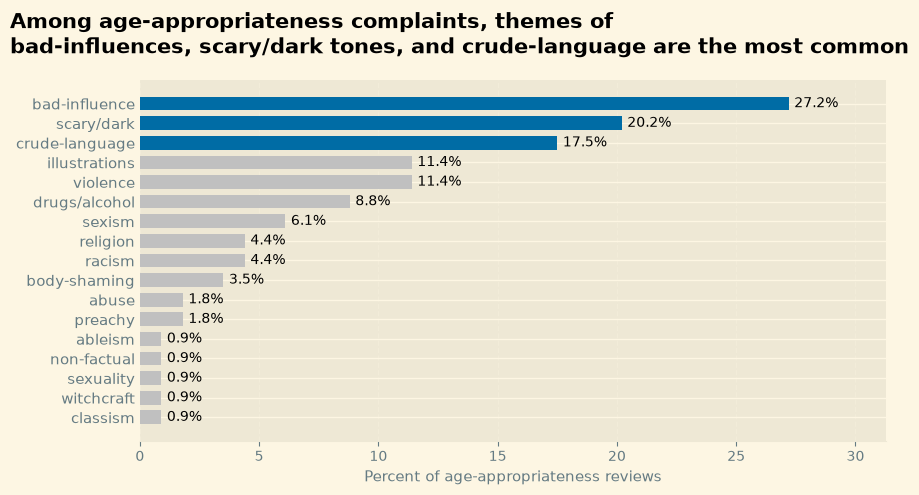

In [34]:
data = pct_others_and_age.sort_values() # sorting values from smallest to largest

highlight = ["bad-influence", "scary/dark", "crude-language"] # highlighting top three themes
colors = ["#006CA5" if label in highlight else "#C0C0C0" for label in data.index]

fig, ax = plt.subplots(figsize=(9, 5)) # sizing the figure
bars = ax.barh(data.index, data.values, color=colors, height=0.7) # creating horizontal bars for each theme

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10) # percent value labels at the end of every bar

# adding title and x/y axis labels
fig.suptitle("Among age-appropriateness complaints, themes of\nbad-influences, scary/dark tones, and crude-language are the most common",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
ax.set_xlabel("Percent of age-appropriateness reviews", fontsize=11)
ax.set_ylabel("")

# cleaning up aesthetics
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, data.max() * 1.15)

plt.tight_layout() # making sure labels don't overlap
plt.show()

##### highlighted in green are the themes/labels that are always paired with age-appropriateness 

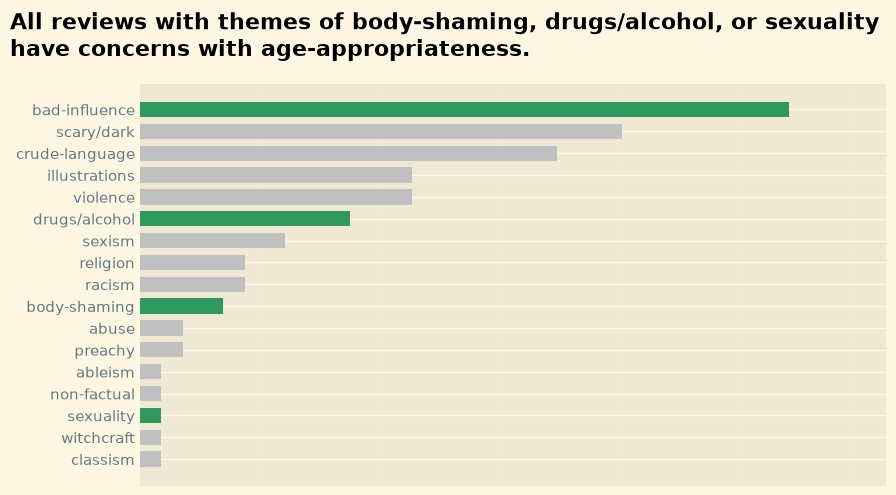

In [35]:
data = pct_others_and_age.sort_values()

highlight = ["bad-influence", "body-shaming", "drugs/alcohol", "sexuality"]
colors = ["#30975d" if label in highlight else "#C0C0C0" for label in data.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(data.index, data.values, color=colors, height=0.7)

fig.suptitle("All reviews with themes of body-shaming, drugs/alcohol, or sexuality\nhave concerns with age-appropriateness.",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
ax.set_xlabel("", fontsize=11)
ax.set_ylabel("")

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, data.max() * 1.15)

plt.tight_layout()
plt.show()

### Visualizing what themes are most common among age-appropriateness complaints

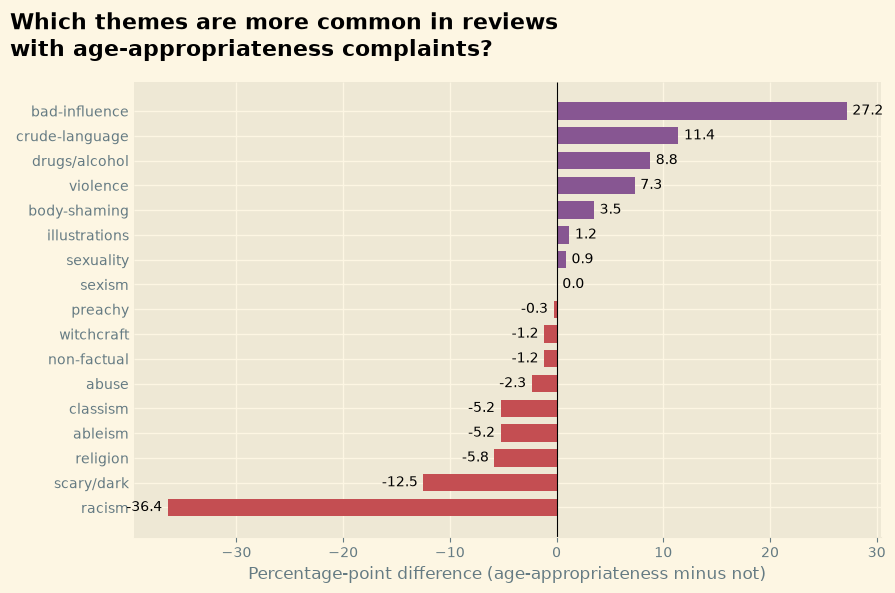

In [36]:
target = "age-appropriateness" # creating an object of the label we're looking at

others = df_inappropriate.explode("labels") # creating an object of other labels. using explode the separate multiple labels in a review into their own rows
others = others[others["labels"] != target].dropna(subset=["labels"]) # dropping target so it won't have a bar

counts = others.groupby(["labels", "has_age"]).size().unstack(fill_value=0) # counting each label and their appearance in "age-appropriateness" reviews
counts = counts.rename(columns={True: "Age-appropriateness", False: "Not age-appropriateness"})

# making a series with the numbers of both groups
group_sizes = pd.Series({ 
    "Age-appropriateness": len(df_age_only),
    "Not age-appropriateness": len(df_not_age),
})
pct = counts / group_sizes * 100

# calculating difference in percentage points
diff = (pct["Age-appropriateness"] - pct["Not age-appropriateness"]).sort_values()

# plotting the data
colors = ["#C44E52" if v < 0 else "#875692" for v in diff]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(diff.index, diff.values, color=colors, height=0.7)
ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Percentage-point difference (age-appropriateness minus not)")
ax.set_ylabel("")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.suptitle("Which themes are more common in reviews\nwith age-appropriateness complaints?",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

#### Split between 1-star reviews about general inappropriateness concerns and children-specific appropriateness concerns

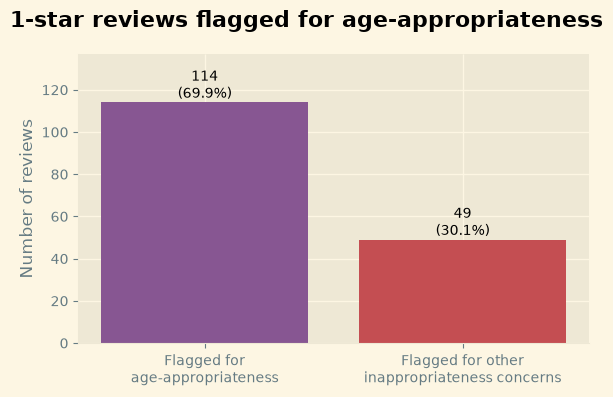

In [37]:
counts = df_inappropriate["has_age"].value_counts().reindex([True, False], fill_value=0)
names = ["Flagged for\nage-appropriateness", "Flagged for other\ninappropriateness concerns"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(names, counts.values, color=["#875692", "#C44E52"])

for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n,
            f"{n}\n({n / num_total:.1%})", ha="center", va="bottom")

ax.set_ylabel("Number of reviews")
ax.set_ylim(0, counts.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("1-star reviews flagged for age-appropriateness",
             x=0.01, ha="left", fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()

### table of most distinctive words in reviews that call something inappropriate

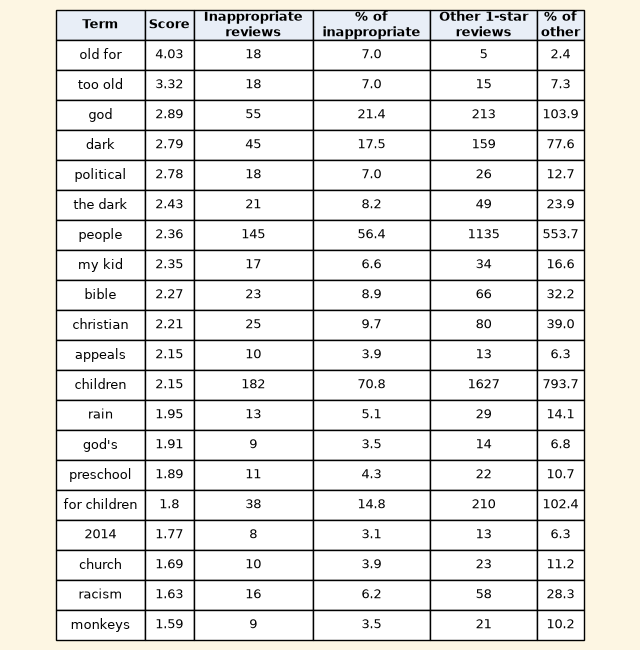

In [38]:
top = (
    distinct[~distinct["term"].str.contains("goodreads|https|www|http|susan|are|oz|lowry|rose")]
    .head(20)
    .copy()
)

table = pd.DataFrame({
    "Term": top["term"],
    "Score": top["score"].round(2),
    "Inappropriate reviews": top["count_A"],
    "% of inappropriate": (top["count_A"] / len(matched) * 100).round(1),
    "Other 1-star reviews": top["count_B"],
    "% of other": (top["count_B"] / len(others) * 100).round(1),
}).reset_index(drop=True)

table.index += 1

display_table = table.copy()
display_table.columns = [
    "Term",
    "Score",
    "Inappropriate\nreviews",
    "% of\ninappropriate",
    "Other 1-star\nreviews",
    "% of\nother",
]

fig, ax = plt.subplots(figsize=(8, 7))
ax.axis("off")
t = ax.table(cellText=display_table.values, colLabels=display_table.columns,
             loc="center", cellLoc="center")
t.auto_set_font_size(False)
t.set_fontsize(9)
t.auto_set_column_width(col=list(range(len(display_table.columns))))
t.scale(1, 1.8)

# make the header row stand out
for j in range(len(display_table.columns)):
    t[0, j].set_text_props(fontweight="bold")
    t[0, j].set_facecolor("#E8EEF7")

plt.savefig("distinctive_terms_table.png", dpi=200, bbox_inches="tight")
plt.show()

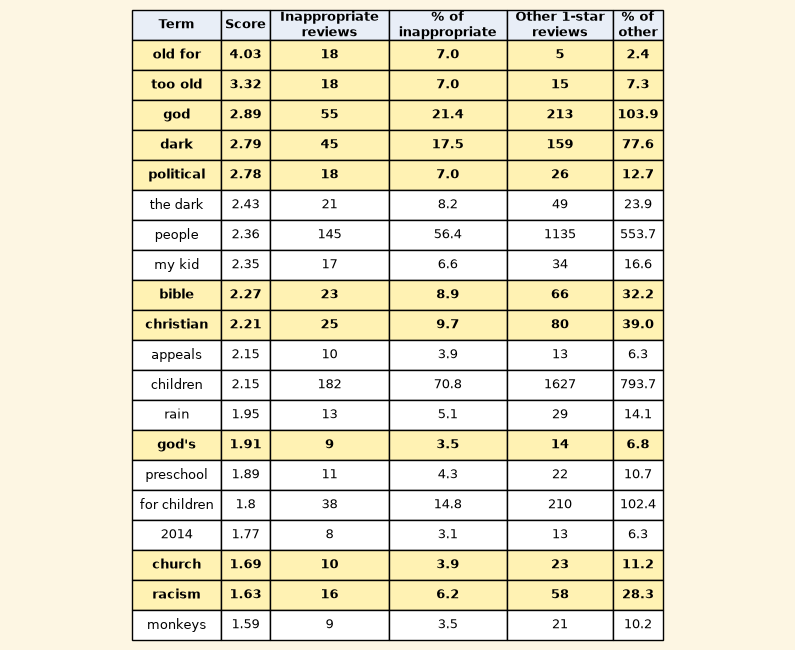

In [39]:
display_table = table.copy()
display_table.columns = [
    "Term",
    "Score",
    "Inappropriate\nreviews",
    "% of\ninappropriate",
    "Other 1-star\nreviews",
    "% of\nother",
]

fig, ax = plt.subplots(figsize=(10, 7))
ax.axis("off")
t = ax.table(cellText=display_table.values, colLabels=display_table.columns,
             loc="center", cellLoc="center")
t.auto_set_font_size(False)
t.set_fontsize(9)
t.auto_set_column_width(col=list(range(len(display_table.columns))))
t.scale(1, 1.8)

HIGHLIGHT = ["bible", "christian", "god's", "god", "political", "dark", "too old", "old for", "church", "racism"]   # <- terms you want to stand out

for i, term in enumerate(display_table["Term"], start=1):   # row 0 is the header, data starts at 1
    if term in HIGHLIGHT:
        for j in range(len(display_table.columns)):
            t[i, j].set_facecolor("#FFF2B3")                 # light yellow
            t[i, j].set_text_props(fontweight="bold")

# make the header row stand out
for j in range(len(display_table.columns)):
    t[0, j].set_text_props(fontweight="bold")
    t[0, j].set_facecolor("#E8EEF7")

plt.savefig("distinctive_terms_table.png", dpi=200, bbox_inches="tight")
plt.show()

In [40]:
n_flagged = len(matched)
n_other = len(others)     # run this while `others` still means the not-flagged reviews

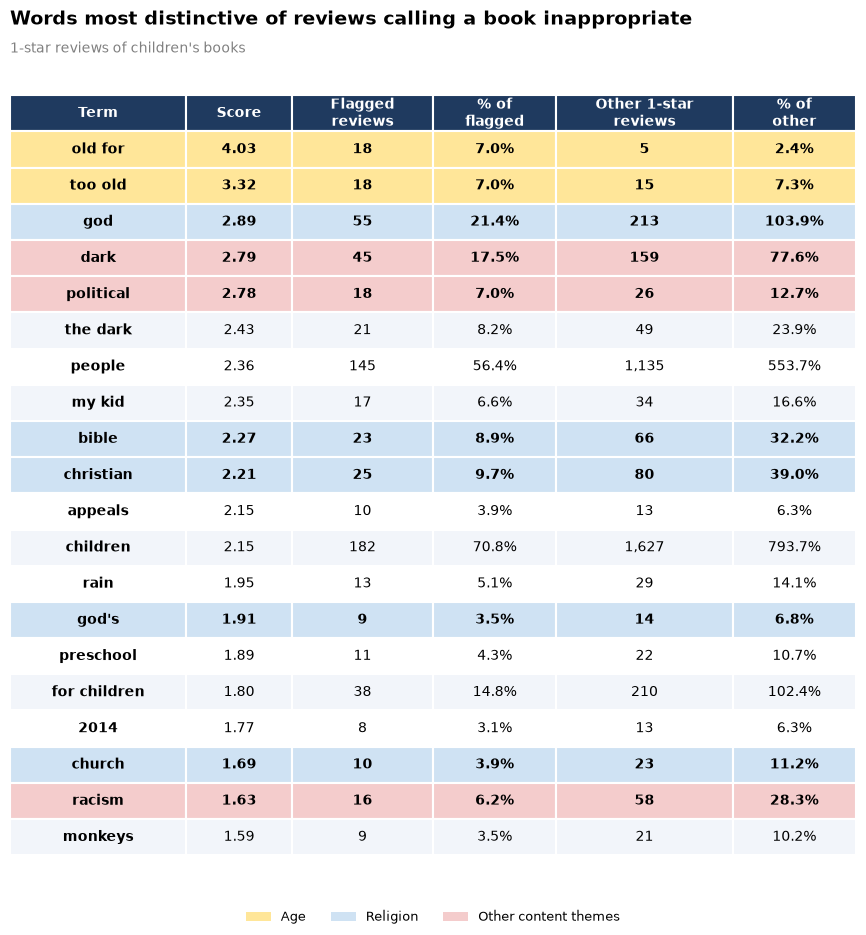

In [ ]:
from matplotlib.patches import Patch

plot_df = table.copy()
plot_df["% flagged"] = plot_df["Inappropriate reviews"] / n_flagged * 100
plot_df["% other"] = plot_df["Other 1-star reviews"] / n_other * 100

cells = [
    [r["Term"], f'{r["Score"]:.2f}',
     f'{r["Inappropriate reviews"]:,}', f'{r["% flagged"]:.1f}%',
     f'{r["Other 1-star reviews"]:,}', f'{r["% other"]:.1f}%']
    for _, r in plot_df.iterrows()
]
headers = ["Term", "Score", "Flagged\nreviews", "% of\nflagged", "Other 1-star\nreviews", "% of\nother"]

AGE, RELIGION, CONTENT = "#FFE699", "#CFE2F3", "#F4CCCC"
HIGHLIGHT = {
    "old for": AGE, "too old": AGE,
    "bible": RELIGION, "christian": RELIGION, "god": RELIGION, "god's": RELIGION, "church": RELIGION,
    "political": CONTENT, "dark": CONTENT, "racism": CONTENT,
}

fig, ax = plt.subplots(figsize=(9, 9.5), facecolor="white")
fig.subplots_adjust(left=0.03, right=0.97, top=0.88, bottom=0.08)
ax.axis("off")

t = ax.table(cellText=cells, colLabels=headers, cellLoc="center",
             colWidths=[0.2, 0.12, 0.16, 0.14, 0.2, 0.14],
             bbox=[0, 0, 1, 1])
t.auto_set_font_size(False)
t.set_fontsize(10)

for (r, c), cell in t.get_celld().items():
    cell.set_edgecolor("white")
    cell.set_linewidth(1.5)
    if r == 0:
        cell.set_facecolor("#1F3A5F")
        cell.set_text_props(color="white", fontweight="bold")
    else:
        term = plot_df["Term"].iloc[r - 1]
        if term in HIGHLIGHT:
            cell.set_facecolor(HIGHLIGHT[term])
            cell.set_text_props(fontweight="bold")
        else:
            cell.set_facecolor("#F2F5FA" if r % 2 == 0 else "#FFFFFF")
        if c == 0:
            cell.set_text_props(fontweight="bold")

fig.suptitle("Words most distinctive of reviews calling a book inappropriate",
             x=0.03, y=0.97, ha="left", fontsize=14, fontweight="bold")
fig.text(0.03, 0.925, "1-star reviews of children's books",
         ha="left", fontsize=10, color="gray")

fig.legend(handles=[Patch(facecolor=AGE, label="Age"),
                    Patch(facecolor=RELIGION, label="Religion"),
                    Patch(facecolor=CONTENT, label="Other content themes")],
           loc="lower center", ncol=3, frameon=False, fontsize=9)

plt.savefig("distinctive_terms_table.png", dpi=200, facecolor="white")
plt.show()